# Pre-snap defensive coverage prediction: progress report code

Group 77, CS/SE 4AL3. This notebook is a self-contained copy of our pipeline: it builds the cleaned dataset from the pre-snap tracking data, splits it by game, trains a majority-class baseline and a Random Forest, and evaluates both on the validation split. The test split is created but never used.

**Running it.** The data is submitted with this notebook in `presnap/`. In Google Colab, choose *Runtime > Run all* and upload the submitted zip when the first cell asks. No extra packages are needed beyond pandas, scikit-learn 1.9.1 and matplotlib, which Colab already provides.

In [5]:
import os
import sys
import glob
import zipfile
import subprocess

# The Random Forest results depend on the scikit-learn version; use the one our report was run with
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.9.1'], check=True)

# Locate the submitted data (presnap/), walking up from here; on Colab, upload the zip if it is missing
def find_data_folder():
    folder = os.getcwd()
    while not os.path.isdir(os.path.join(folder, 'presnap')):
        parent = os.path.dirname(folder)
        if parent == folder:
            return None
        folder = parent
    return folder

data_folder = find_data_folder()
if data_folder is None and 'google.colab' in sys.modules:
    from google.colab import files
    print('Upload the submitted zip (it contains presnap/).')
    for name in files.upload():
        if name.endswith('.zip'):
            zipfile.ZipFile(name).extractall('submission')
    found = glob.glob('**/presnap/plays.csv', recursive=True)
    if found:
        data_folder = os.path.abspath(os.path.join(os.path.dirname(found[0]), '..'))
if data_folder is None:
    raise FileNotFoundError('presnap/ not found; run from the folder that contains presnap/')
os.chdir(data_folder)
print('Data folder:', os.path.basename(os.getcwd()))

Data folder: content


## 1. Imports

In [6]:
import csv
import math
import tempfile
from pathlib import Path
from statistics import median
from collections.abc import Iterator, Mapping
from os import PathLike

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import pandas as pd

import sklearn
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)
if sklearn.__version__ != '1.9.1':
    print('Warning: results in our report use scikit-learn 1.9.1; on Colab, restart the runtime and run all.')

scikit-learn 1.9.1 | pandas 2.2.3


## 2. Column definitions

The output columns: game context and personnel from the play data, 37 alignment features engineered from the tracking data, and the coverage label.

In [7]:
play_to_coverage: dict[tuple[str, str], str] = {}

play_to_tracking: dict[tuple[str, str], list[dict[str, str]]] = {}

ALIGNMENT_FIELDS = [
    'defense_deepest_depth', 'defense_second_deepest_depth',
    'defense_deep_pair_lateral_spacing', 'defense_width',
    'defenders_beyond_5_yards', 'defenders_beyond_10_yards',
    'defenders_beyond_15_yards', 'offense_width',
    'offense_left_count', 'offense_right_count', 'offense_backfield_count',
    'offense_wide_count', 'wide_offense_nearest_defender_mean',
    'wide_offense_nearest_defender_min', 'wide_offense_nearest_defender_max',
    *[f'defender_{rank}_{axis}' for rank in range(1, 12)
      for axis in ('depth', 'lateral')],
]


fields: list[str] = [
    'game_id',
    'offensive_team',
    'defensive_team',
    'quarter',
    'game_clock',
    'score_gap',
    'down',
    'yards_to_fd',
    'yards_to_goal',
    'offensive_line',
    'wide_recievers',
    'running_backs',
    'tight_ends',
    'formation',
    'defensive_line',
    'line_backers',
    'defensive_backs',
    'defenders_in_box',
    *ALIGNMENT_FIELDS,
    'defensive_coverage',
]

ACTIVE_PLAYERS_ON_FIELD: int = 11

## 3. Reading the data

Labels and tracking snapshots are keyed by both game and play ID, because `playId` alone repeats across games.

In [8]:
def assign_labels(file_path: str | PathLike[str]) -> None:
    with open(file_path, 'r') as f:
        for row in csv.DictReader(f):
            play_to_coverage[(row['gameId'], row['playId'])] = row['pff_passCoverage']

def distance_to_goal(offense: str, yardline_side: str, yardline_number: str | int) -> int:
    if offense == yardline_side:
        return 100 - int(yardline_number)
    return int(yardline_number)

def extract_play_info(file_path: str | PathLike[str]) -> Iterator[dict[str, str]]:
    with open(file_path, 'r') as f:
        for row in csv.DictReader(f):
            yield row

def assign_tracking(file_path: str | PathLike[str]) -> None:
    """Index player snapshots by game AND play; do not use row order as identity."""
    play_to_tracking.clear()
    for row in extract_play_info(file_path):
        key = (row['gameId'], row['playId'])
        play_to_tracking.setdefault(key, []).append(row)

## 4. Alignment features

Geometry of the last pre-snap frame: depth from the line of scrimmage, lateral spacing, and distances between players. These are engineered by us from the raw tracking coordinates.

In [9]:
def alignment_features(data: Mapping[str, str]) -> dict[str, float | int]:
    """Describe one complete pre-snap snapshot, in yards and offense-relative axes.

    Positive depth is downfield from the line of scrimmage. Rotate leftward
    plays 180 degrees, then center lateral coordinates on the offense's median
    lateral position (a proxy for formation center, NOT the football).
    Wide players are >5 yards from this center; backfield players are >1 yard
    behind the line. These are geometric categories, not player position labels.
    """
    rows = play_to_tracking.get((data['gameId'], data['playId']), [])
    if len(rows) != 22 or len({r['nflId'] for r in rows}) != 22:
        raise ValueError('Expected 22 distinct tracked players')
    if len({r['frameId'] for r in rows}) != 1 or len({r['snapFrame'] for r in rows}) != 1:
        raise ValueError('Expected a single snapshot and snap frame')
    if any(int(r['frameId']) >= int(r['snapFrame']) for r in rows):
        raise ValueError('Tracking must be strictly before the snap')
    directions = {r['playDirection'] for r in rows}
    if len(directions) != 1 or not directions <= {'left', 'right'}:
        raise ValueError('Invalid or inconsistent play direction')
    sign = 1 if rows[0]['playDirection'] == 'right' else -1
    # Derive the line when the source coordinate is missing.
    distance = distance_to_goal(data['possessionTeam'], data['yardlineSide'], data['yardlineNumber'])
    los = float(data['absoluteYardlineNumber']) if data.get('absoluteYardlineNumber') else (
        110 - distance if sign == 1 else 10 + distance
    )
    offense, defense = [], []
    for row in rows:
        side = int(row['isDefense'])
        if side not in (0, 1):
            raise ValueError('Invalid isDefense flag')
        expected_team = data['defensiveTeam'] if side else data['possessionTeam']
        if row['team'] != expected_team:
            raise ValueError('Tracking team does not match play context')
        depth, lateral = sign * (float(row['x']) - los), sign * float(row['y'])
        if not all(math.isfinite(v) for v in (depth, lateral)):
            raise ValueError('Non-finite player coordinate')
        (defense if side else offense).append((depth, lateral))
    if len(offense) != 11 or len(defense) != 11:
        raise ValueError('Expected 11 players per team')
    center = median(y for _, y in offense)
    offense = [(x, y - center) for x, y in offense]
    defense = sorted(((x, y - center) for x, y in defense), key=lambda xy: (-xy[0], xy[1]))
    wide = [(x, y) for x, y in offense if abs(y) > 5]
    distances = [min(math.hypot(x - dx, y - dy) for dx, dy in defense) for x, y in wide]
    result = {
        'defense_deepest_depth': defense[0][0],
        'defense_second_deepest_depth': defense[1][0],
        'defense_deep_pair_lateral_spacing': abs(defense[0][1] - defense[1][1]),
        'defense_width': max(y for _, y in defense) - min(y for _, y in defense),
        **{f'defenders_beyond_{threshold}_yards': sum(x > threshold for x, _ in defense)
           for threshold in (5, 10, 15)},
        'offense_width': max(y for _, y in offense) - min(y for _, y in offense),
        'offense_left_count': sum(y > 0 for _, y in offense),
        'offense_right_count': sum(y < 0 for _, y in offense),
        'offense_backfield_count': sum(x < -1 for x, _ in offense),
        'offense_wide_count': len(wide),
        # Zero distances mean no wide players only when offense_wide_count == 0.
        'wide_offense_nearest_defender_mean': sum(distances) / len(distances) if distances else 0.0,
        'wide_offense_nearest_defender_min': min(distances, default=0.0),
        'wide_offense_nearest_defender_max': max(distances, default=0.0),
    }
    for rank, (depth, lateral) in enumerate(defense, start=1):
        result[f'defender_{rank}_depth'] = depth
        result[f'defender_{rank}_lateral'] = lateral
    return result

## 5. Cleaning one play

Personnel counts come from the PFF personnel strings.

In [10]:
def transform_data(data: Mapping[str, str]) -> dict[str, str | int | float]:
    raw_personal = data['personnelO'].split(' ')
    qb_on_field = 1

    if len(raw_personal) == 4:
        oline_on_field = int(raw_personal[0])
        rb_on_field = int(raw_personal[2])
        te_on_field = int(raw_personal[4])
        wr_on_field = int(raw_personal[6])
    else:
        rb_on_field = int(raw_personal[0])
        te_on_field = int(raw_personal[2])
        wr_on_field = int(raw_personal[4])

        oline_on_field = ACTIVE_PLAYERS_ON_FIELD - rb_on_field - te_on_field - wr_on_field - qb_on_field


    raw_personal = data['personnelD'].split(' ')
    dl_on_field = int(raw_personal[0])
    lb_on_field = int(raw_personal[2])
    db_on_field = int(raw_personal[4])

    endzone_distance = distance_to_goal(data['possessionTeam'], data['yardlineSide'], data['yardlineNumber'])
    minutes, seconds = data["gameClock"].split(":")
    game_clock = int(minutes) * 60 + int(seconds)

    return {
        'game_id' : data['gameId'],
        # Game situation
        'offensive_team' : data['possessionTeam'],
        'defensive_team' : data['defensiveTeam'],
        'quarter' : int(data['quarter']),
        'game_clock' : game_clock,
        'score_gap' : abs(int(data['preSnapHomeScore']) - int(data['preSnapVisitorScore'])),


        'down' : int(data['down']),
        'yards_to_fd' : int(data['yardsToGo']),
        'yards_to_goal' : endzone_distance,

        # Offensive formations
        'offensive_line' : oline_on_field,
        'wide_recievers' : wr_on_field,
        'running_backs' : rb_on_field,
        'tight_ends' : te_on_field,
        'formation' : data['offenseFormation'],

        # Defensive formations
        'defensive_line' : dl_on_field,
        'line_backers' : lb_on_field,
        'defensive_backs' : db_on_field,
        'defenders_in_box': data['defendersInBox'],

        # Pre-snap player geometry
        **alignment_features(data),

        #Target
        'defensive_coverage' : play_to_coverage[(data['gameId'],data['playId'])]
    }

def validate_transformation(cleaned_data) -> bool:
    for v in cleaned_data.values():
        if v is None or v == '':
            return False
    return True

def load(file_path: str | PathLike[str], cleaned_data: Mapping[str, str | int | float]) -> None:
    with open(file_path, mode='a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=cleaned_data.keys())
        writer.writerow(cleaned_data)

## 6. Build the cleaned dataset

In [11]:
# Written to a temporary file so the repository's data stays untouched
output_path = os.path.join(tempfile.gettempdir(), 'cleaned_data.csv')

Path(output_path).parent.mkdir(parents=True, exist_ok=True)
assign_tracking('presnap/tracking.csv')

with open(output_path, mode='w', encoding='utf-8') as f:
    f.write(",".join(fields) + '\n')


assign_labels('presnap/labels.csv')

written = skipped = 0
for play in extract_play_info('presnap/plays.csv'):
    try:
        cleaned_data = transform_data(play)
        if validate_transformation(cleaned_data):
            load(output_path, cleaned_data)
            written += 1
        else:
            skipped += 1
    except ValueError as e:
        skipped += 1
        print(f"Skipped {play['gameId']}/{play['playId']}: {e}")
print(f"Wrote {written} plays; skipped {skipped}; added {len(ALIGNMENT_FIELDS)} alignment features.")

Skipped 2021091904/3676: invalid literal for int() with base 10: ''
Wrote 8515 plays; skipped 7; added 37 alignment features.


## 7. Dataset summary

In [12]:
df = pd.read_csv(output_path)
print('Plays:', len(df), '| Games:', df['game_id'].nunique(), '| Columns:', df.shape[1])
print(df['defensive_coverage'].value_counts())

Plays: 8515 | Games: 122 | Columns: 56
defensive_coverage
Cover-3          2655
Cover-1          2003
Cover-2          1078
Quarters         1024
Cover-6           801
Red Zone          376
Cover-0           270
2-Man             197
Bracket            46
Prevent            32
Goal Line          25
Miscellaneous       8
Name: count, dtype: int64


## 8. Train, validation, and test split

Split by game so no game appears in more than one partition. The test split is created but never used here.

In [13]:
df = pd.read_csv(output_path)

def retrieve_data_sets():
    # 70% training, 30% remaining
    split = GroupShuffleSplit(
        n_splits=1, train_size=0.70, random_state=42
    )

    train_idx, remaining_idx = next(
        split.split(df, groups=df['game_id'])
    )

    train_df = df.iloc[train_idx].copy().drop(columns=['game_id'])
    remaining_df = df.iloc[remaining_idx].copy()

    # Split remaining games equally: 15% validation, 15% test
    split = GroupShuffleSplit(
        n_splits=1, test_size=0.50, random_state=42
    )
    val_idx, test_idx = next(
        split.split(remaining_df, groups=remaining_df['game_id'])
    )

    val_df = remaining_df.iloc[val_idx].copy().drop(columns=['game_id'])
    test_df = remaining_df.iloc[test_idx].copy().drop(columns=['game_id'])
    return train_df, val_df, test_df


train_df, val_df, test_df = retrieve_data_sets()
print('Plays (train/validation/test):', len(train_df), len(val_df), len(test_df))

Plays (train/validation/test): 5921 1279 1315


## 9. Majority-class baseline

Predicts the most frequent training class for every play.

In [14]:
# Fitted on training labels, scored on validation labels
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train_df.drop(columns=['defensive_coverage']), train_df['defensive_coverage'])
baseline_pred = baseline.predict(val_df.drop(columns=['defensive_coverage']))

print("Accuracy:", accuracy_score(val_df['defensive_coverage'], baseline_pred))
print("Macro F1:", f1_score(
    val_df['defensive_coverage'], baseline_pred, average="macro", zero_division=0
))

Accuracy: 0.29319781078967944
Macro F1: 0.037787182587666265


## 10. Random Forest

These hyperparameters come from an earlier validation search, run before the alignment features existed (see section 12 and `benchmarks/` in the repository).

In [15]:
def train_model(train_df):
    X, y = train_df.drop(columns=['defensive_coverage']), train_df['defensive_coverage']
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                make_column_selector(dtype_include=["object", "string", "category"]),
            )
        ],
        remainder="passthrough",
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            # Selected by validation search; see benchmarks/2026-11-08-random-forest-search/.
            n_estimators=300,
            max_depth=20,
            max_features="log2",
            min_samples_leaf=1,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced",
        )),
    ])

    model.fit(X, y)
    return model


def validation(train_df, validation_df):
    model = train_model(train_df)
    X_val, y_val = validation_df.drop(columns=['defensive_coverage']), validation_df['defensive_coverage']
    y_pred = model.predict(X_val)

    print("Accuracy:", accuracy_score(y_val, y_pred))
    print("Macro F1:", f1_score(
        y_val, y_pred, average="macro", zero_division=0
    ))

    print(classification_report(y_val, y_pred, zero_division=0))

    fig, ax = plt.subplots(figsize=(8, 6.5))
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        normalize="true",
        xticks_rotation=45,
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    for text in ax.texts:
        text.set_fontsize(8)
    plt.tight_layout()
    plt.show()

## 11. Validation results

Accuracy, macro-F1, per-class report, and the normalized confusion matrix.

Accuracy: 0.5019546520719312
Macro F1: 0.44158026197357775
               precision    recall  f1-score   support

        2-Man       0.33      0.13      0.19        45
      Bracket       0.00      0.00      0.00         8
      Cover-0       0.43      0.57      0.49        63
      Cover-1       0.58      0.66      0.62       326
      Cover-2       0.38      0.26      0.31       152
      Cover-3       0.62      0.43      0.51       375
      Cover-6       0.30      0.36      0.32        89
    Goal Line       0.86      1.00      0.92         6
Miscellaneous       0.00      0.00      0.00         2
      Prevent       0.67      1.00      0.80         2
     Quarters       0.43      0.64      0.51       162
     Red Zone       0.49      0.86      0.63        49

     accuracy                           0.50      1279
    macro avg       0.42      0.49      0.44      1279
 weighted avg       0.51      0.50      0.49      1279



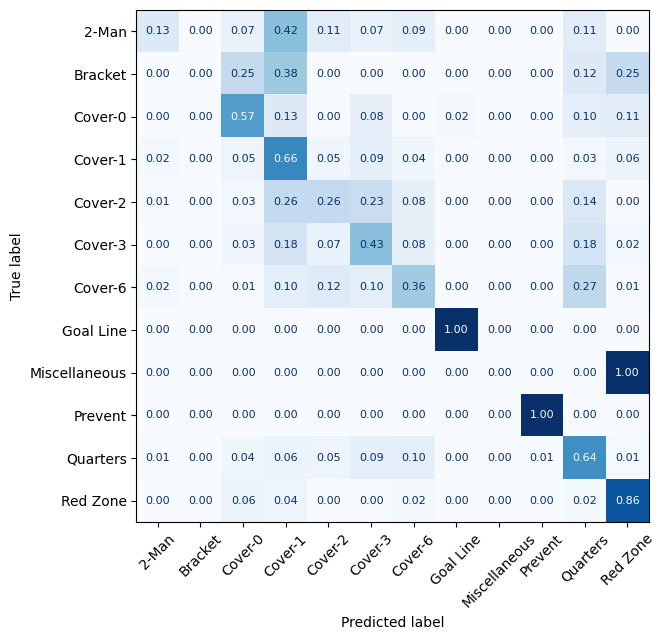

In [16]:
validation(train_df, val_df)

## 12. Hyperparameter search

A staged search on the validation split (the test split is never fitted or scored): class weights, depth and leaf size, features per split, tree count, then the top three configurations re-checked at two more seeds. It takes about a minute or two.

The settings used in section 10 (300 trees, depth 20, `log2` features, balanced class weights) came from this search when it was first run, before the alignment features were added. Re-running it here on the final feature set picks a different top configuration, but the finalists are essentially tied at a mean validation macro-F1 of about 0.44, the same as the section 10 model (0.439). We kept the section 10 settings; we plan to re-tune inside cross-validation.

In [17]:
import json
import time
from itertools import product

import numpy as np


def main():
    df = pd.read_csv(output_path)
    train_i, remaining_i = next(GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42).split(df, groups=df.game_id))
    train, remaining = df.iloc[train_i], df.iloc[remaining_i]
    val_i, test_i = next(GroupShuffleSplit(n_splits=1, test_size=.5, random_state=42).split(remaining, groups=remaining.game_id))
    val = remaining.iloc[val_i]
    groups = [set(train.game_id), set(val.game_id), set(remaining.iloc[test_i].game_id)]
    assert all(not groups[a] & groups[b] for a, b in [(0, 1), (0, 2), (1, 2)])
    features = df.columns.drop(["game_id", "defensive_coverage"]).tolist()
    assert {"offensive_team", "defensive_team"} <= set(features)
    preprocessing = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         make_column_selector(dtype_include=["object", "string", "category"]))
    ], remainder="passthrough")
    X = preprocessing.fit_transform(train[features])
    V = preprocessing.transform(val[features])
    y, vy = train.defensive_coverage, val.defensive_coverage
    labels = sorted(set(y) | set(vy))
    runs = []
    base = dict(n_estimators=100, max_depth=None, min_samples_leaf=1,
                max_features="sqrt", class_weight="balanced", random_state=42, n_jobs=-1)

    def run(params, stage, reason):
        start = time.perf_counter()
        model = RandomForestClassifier(**params).fit(X, y)
        pred = model.predict(V)
        record = dict(id=len(runs)+1, stage=stage, reason=reason, parameters=params.copy(),
                      seconds=round(time.perf_counter()-start, 3),
                      validation_accuracy=accuracy_score(vy, pred),
                      validation_macro_f1=f1_score(vy, pred, labels=labels, average="macro", zero_division=0),
                      training_macro_f1=f1_score(y, model.predict(X), labels=labels, average="macro", zero_division=0),
                      classification_report=classification_report(vy, pred, labels=labels, output_dict=True, zero_division=0))
        runs.append(record)
        print(f"Run {record['id']:02}: {stage}; macro-F1={record['validation_macro_f1']:.4f}; accuracy={record['validation_accuracy']:.4f}", flush=True)
        return record

    # Controlled grid: isolate weighting and regularization, then test interactions.
    for weight, depth, leaf in product([None, "balanced", "balanced_subsample"], [None, 10, 20], [1, 3, 5, 10]):
        run(dict(base, class_weight=weight, max_depth=depth, min_samples_leaf=leaf), "weight-depth-leaf",
            "Compare unweighted and inverse-frequency weighting; depth 10/20 and larger leaves constrain memorization, with unrestricted depth/leaf 1 as controls.")
    best = max(runs, key=lambda r: (r["validation_macro_f1"], r["validation_accuracy"]))
    for features_per_split in ["log2", .5, None]:
        run(dict(best["parameters"], max_features=features_per_split), "feature-sampling",
            "Test whether considering fewer or more encoded features per split improves useful interactions versus tree diversity; sqrt is the existing control.")
    best = max(runs, key=lambda r: (r["validation_macro_f1"], r["validation_accuracy"]))
    for count in [300, 500]:
        run(dict(best["parameters"], n_estimators=count), "tree-count",
            "Check whether more trees stabilize probabilities and improve validation performance; 100 trees is the control.")
    finalists = sorted(runs, key=lambda r: (r["validation_macro_f1"], r["validation_accuracy"]), reverse=True)[:3]
    summaries = []
    for candidate in finalists:
        repeated = [candidate] + [run(dict(candidate["parameters"], random_state=seed), "seed-check",
                                    f"Check seed sensitivity of finalist run {candidate['id']} on the same validation games.") for seed in [7, 123]]
        summaries.append(dict(initial_run=candidate["id"], parameters=candidate["parameters"],
                              run_ids=[r["id"] for r in repeated],
                              mean_macro_f1=float(np.mean([r["validation_macro_f1"] for r in repeated])),
                              std_macro_f1=float(np.std([r["validation_macro_f1"] for r in repeated])),
                              mean_accuracy=float(np.mean([r["validation_accuracy"] for r in repeated]))))
    summaries.sort(key=lambda r: (r["mean_macro_f1"], r["mean_accuracy"]), reverse=True)
    majority = y.value_counts().idxmax()
    bp = np.repeat(majority, len(vy))
    print("Baseline: accuracy=%.4f; macro-F1=%.4f" % (accuracy_score(vy, bp), f1_score(vy, bp, labels=labels, average="macro", zero_division=0)))
    print("BEST: " + json.dumps(summaries[0]), flush=True)
    return runs, summaries

In [18]:
runs, summaries = main()

Run 01: weight-depth-leaf; macro-F1=0.4091; accuracy=0.5223
Run 02: weight-depth-leaf; macro-F1=0.3962; accuracy=0.5192
Run 03: weight-depth-leaf; macro-F1=0.3756; accuracy=0.5098
Run 04: weight-depth-leaf; macro-F1=0.2701; accuracy=0.5098
Run 05: weight-depth-leaf; macro-F1=0.3201; accuracy=0.5004
Run 06: weight-depth-leaf; macro-F1=0.3182; accuracy=0.5035
Run 07: weight-depth-leaf; macro-F1=0.3528; accuracy=0.5059
Run 08: weight-depth-leaf; macro-F1=0.3406; accuracy=0.5074
Run 09: weight-depth-leaf; macro-F1=0.4051; accuracy=0.5160
Run 10: weight-depth-leaf; macro-F1=0.3896; accuracy=0.5152
Run 11: weight-depth-leaf; macro-F1=0.3715; accuracy=0.5098
Run 12: weight-depth-leaf; macro-F1=0.2702; accuracy=0.5090
Run 13: weight-depth-leaf; macro-F1=0.4311; accuracy=0.5090
Run 14: weight-depth-leaf; macro-F1=0.4025; accuracy=0.4879
Run 15: weight-depth-leaf; macro-F1=0.3992; accuracy=0.4848
Run 16: weight-depth-leaf; macro-F1=0.4102; accuracy=0.4801
Run 17: weight-depth-leaf; macro-F1=0.43

The finalists, ranked by mean validation macro-F1 across the three seeds:

In [19]:
pd.DataFrame([
    dict(max_depth=s["parameters"]["max_depth"], min_samples_leaf=s["parameters"]["min_samples_leaf"],
         max_features=s["parameters"]["max_features"], n_estimators=s["parameters"]["n_estimators"],
         class_weight=s["parameters"]["class_weight"],
         mean_macro_f1=round(s["mean_macro_f1"], 4), std_macro_f1=round(s["std_macro_f1"], 4),
         mean_accuracy=round(s["mean_accuracy"], 4))
    for s in summaries
])

,max_depth,min_samples_leaf,max_features,n_estimators,class_weight,mean_macro_f1,std_macro_f1,mean_accuracy
0,20.0,3,sqrt,100,balanced_subsample,0.4419,0.0062,0.5069
1,20.0,1,sqrt,100,balanced,0.4372,0.0199,0.4983
2,NaN,3,sqrt,100,balanced_subsample,0.4360,0.0035,0.5119


## Notes

- All numbers above are validation results; the test split has not been scored.
- The alignment features describe geometry only. The tracking data has no player-position column, so the features cannot tell a safety from a cornerback.
- Team names are still model inputs, and the score gap is the absolute difference.
- Next steps: grouped 5-fold cross-validation, gradient-boosted trees, player roles as features, and per-class optimization.